# Montessori Schools in Official School Registries: Starter Notebook

A first look at the dataset by **Montessori School Finder**. Companion directory: [montessorischoolfinder.com](https://www.montessorischoolfinder.com/). Licence CC BY 4.0, with the registry licences listed in the README.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Local copy first, then the GitHub raw files
import os
base = 'data' if os.path.exists('data/montessori_schools_official_registries.csv') else '../data' if os.path.exists('../data/montessori_schools_official_registries.csv') else '/kaggle/input/montessori-schools-official-registries' if os.path.exists('/kaggle/input/montessori-schools-official-registries') else 'https://raw.githubusercontent.com/montessoritheory/montessori-schools-official-registries/main/data'
schools = pd.read_csv(f'{base}/montessori_schools_official_registries.csv', dtype=str).fillna('')
print(len(schools), 'open schools')
schools.head()

410 open schools


,country,country_code,registry,official_id,name,type_phase,registry_category,public_or_private,status,address,postcode,city,region,latitude,longitude,age_range_or_phase,source_url,retrieved_at,match_reason,msf_city_url
0,England,GB-ENG,Get Information About Schools (Department for ...,131978,Maria Montessori School,Other independent school,Independent schools,Private (independent),Open,26 Lyndhurst Gardens,NW3 5NW,London,London,,,3-16,https://get-information-schools.service.gov.uk...,2026-11-17,name contains Montessori,https://www.montessorischoolfinder.com/locatio...
1,England,GB-ENG,Get Information About Schools (Department for ...,133086,Wildwood Montessori School,Miscellaneous,Other types,Not stated,Open,"10 Greta House, 60 Hardy Road, Greenwich",SE3 7PA,London,London,,,,https://get-information-schools.service.gov.uk...,2026-11-17,name contains Montessori,https://www.montessorischoolfinder.com/locatio...
2,England,GB-ENG,Get Information About Schools (Department for ...,135995,The Deenway Montessori School,Other independent school,Independent schools,Private (independent),Open,"3-5 Sidmouth Street, Reading",RG1 4QZ,,South East,,,3-16,https://get-information-schools.service.gov.uk...,2026-11-17,name contains Montessori,
3,England,GB-ENG,Get Information About Schools (Department for ...,136947,The Montessori Place,Other independent school,Independent schools,Private (independent),Open,45 Cromwell Road,BN3 3ER,Hove,South East,,,1-18,https://get-information-schools.service.gov.uk...,2026-11-17,name contains Montessori,https://www.montessorischoolfinder.com/locatio...
4,England,GB-ENG,Get Information About Schools (Department for ...,131567,St Helens Montessori School,Other independent school,Independent schools,Private (independent),Open,"Lower Road, East Farleigh",ME15 0JT,Maidstone,South East,,,2-12,https://get-information-schools.service.gov.uk...,2026-11-17,name contains Montessori,https://www.montessorischoolfinder.com/locatio...


## Schools by country

In [2]:
schools.groupby(['country', 'registry']).size().rename('schools').reset_index().sort_values('schools', ascending=False)

,country,registry,schools
1,France,Annuaire de l'education (Ministere de l'Educat...,245
2,Netherlands,DUO Open Onderwijsdata (Dienst Uitvoering Onde...,154
0,England,Get Information About Schools (Department for ...,10
3,Wales,Get Information About Schools (Department for ...,1


## Biggest regions

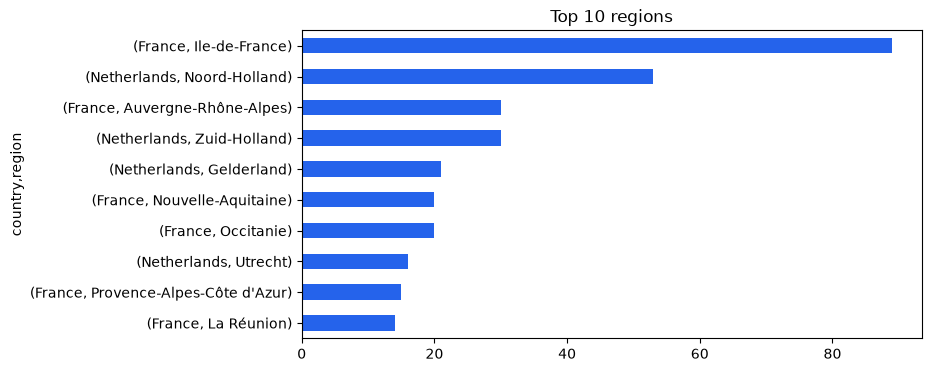

In [3]:
top = schools.groupby(['country', 'region']).size().rename('schools').sort_values(ascending=False).head(10)
top.sort_values().plot.barh(color='#2563eb', figsize=(8, 4), title='Top 10 regions')
plt.show()

## Public or private

In [4]:
pd.crosstab(schools.country, schools.public_or_private)

public_or_private,Not stated,Private,Private (independent),Public,"Publicly funded, special or denominational"
country,,,,,
England,1,0,9,0,0
France,0,234,0,11,0
Netherlands,0,0,0,50,104
Wales,1,0,0,0,0


## Cities with the most schools

In [5]:
by_city = pd.read_csv(f'{base}/by_city.csv')
by_city.head(10)

,country,region,city,schools
0,Netherlands,Noord-Holland,Amsterdam,28
1,Netherlands,Zuid-Holland,'s-Gravenhage,10
2,France,Ile-de-France,Paris 15e Arrondissement,7
3,France,La Réunion,Saint-Denis,5
4,Netherlands,Gelderland,Nijmegen,5
5,Netherlands,Zuid-Holland,Rotterdam,5
6,France,Pays de la Loire,Angers,4
7,France,Ile-de-France,Bailly,4
8,France,Ile-de-France,Paris 17e Arrondissement,4
9,France,Ile-de-France,Paris 7e Arrondissement,4


## French schools on a map (registry coordinates)

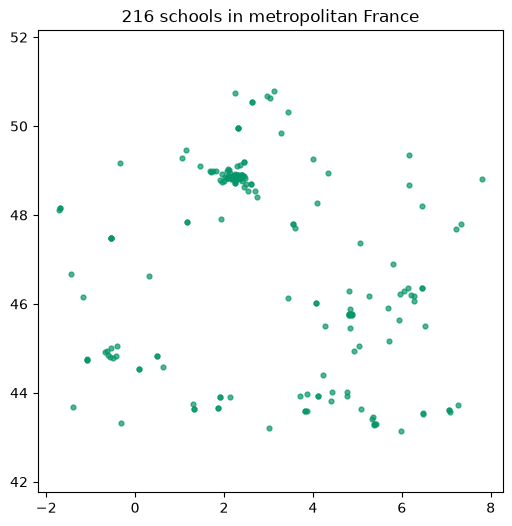

In [6]:
fr = schools[(schools.country == 'France') & (schools.latitude != '')].copy()
fr['latitude'] = fr.latitude.astype(float); fr['longitude'] = fr.longitude.astype(float)
metro = fr[(fr.longitude > -6) & (fr.longitude < 10) & (fr.latitude > 41)]
plt.figure(figsize=(6, 6)); plt.scatter(metro.longitude, metro.latitude, s=12, c='#059669', alpha=.7)
plt.title(f'{len(metro)} schools in metropolitan France'); plt.axis('equal'); plt.show()

## Schools with a Montessori School Finder city page

In [7]:
linked = schools[schools.msf_city_url != '']
print(len(linked), 'of', len(schools), 'schools link to a city page')
linked[['country', 'city', 'msf_city_url']].drop_duplicates().head(10)

320 of 410 schools link to a city page


,country,city,msf_city_url
0,England,London,https://www.montessorischoolfinder.com/locatio...
3,England,Hove,https://www.montessorischoolfinder.com/locatio...
4,England,Maidstone,https://www.montessorischoolfinder.com/locatio...
5,England,Oxford,https://www.montessorischoolfinder.com/locatio...
7,England,Tadley,https://www.montessorischoolfinder.com/locatio...
8,England,Henley-in-Arden,https://www.montessorischoolfinder.com/locatio...
9,England,Skipton,https://www.montessorischoolfinder.com/locatio...
12,France,Chevry,https://www.montessorischoolfinder.com/locatio...
13,France,Cranves-Sales,https://www.montessorischoolfinder.com/locatio...
14,France,Divonne-les-Bains,https://www.montessorischoolfinder.com/locatio...


## Read with care

Schools are selected because **Montessori is in the official name**. A registry does not check the teaching method, and schools that use the method without the word in their name are not here. Most English Montessori settings are nurseries outside GIAS, so the English count is small.